Sveučilište u Zagrebu  
Fakultet elektrotehnike i računarstva  
  
## Multivarijatna analiza podataka - ak. god. 2024/2025  
https://www.fer.unizg.hr/predmet/map_a

### Prva laboratorijska vježba - Geometrija uzorka, slučajno uzorkovanje, multivarijatna normalna razdioba, statističko zaključivanje

**Rok za predaju: 6. travnja 2025. u 23:59h**

------------------------------

### Uvod i upute za predaju

Rješavanje vježbe svodi se na čitanje uputa u ćelijama s tekstom, nadopunjavanje blokova kôda (možete dodavati i dodatne blokove kôda ukoliko je potrebno) i ispisivanje rezultata (u vidu ispisa iz funkcija, tablica i grafova). Pritom morate razumjeti teorijske osnove implementiranih rješenja, u okviru onoga što je obrađeno na predavanjima. Kôd možete pisati u Pythonu ili R-u. Ako koristite R, instalirajte potrebne alate za njegovo pokretanje u Jupyter bilježnici (npr. [link](https://www.freecodecamp.org/news/how-to-run-r-programs-directly-in-jupyter-notebook-locally/)). Osim ako u određenom zadatku ne piše drugačije, za implementaciju rješenja možete koristiti proizvoljne biblioteke.

**Predaja**: Vaše rješenje potrebno je predati u sustav _Moodle_ u obliku .ipynb datoteke naziva IME_PREZIME_JMBAG.ipynb. Rok za predaju je 6. travnja 2025. u 23:59.

**Bodovanje**: Svoje rješenje branite usmeno na terminima koji su vam dodijeljeni u kalendaru. Vježba nosi 10 bodova, pri čemu je naglasak na usmenoj obrani i interpretaciji rješenja.  Napominjemo da će se prilikom ocjenjivanja strogo provjeravati originalnost vaših rješenja. Predstavljanje tuđeg rada kao vlastitog je kršenje kodeksa ponašanja studenata i takvi slučajevi bit će prijavljeni povjerenstvu za stegovnu odgovornost.

**Napomena**: Podsjećamo da bodovi iz laboratorijskih vježbi ulaze i u bodove na ispitnom roku, te da je za polaganje predmeta potrebno ostvariti barem 10 od ukupnih 30 bodova iz laboratorijskih vježbi. Nadoknade laboratorijskih vježbi neće biti organizirane.

Za sva dodatna pitanja javite se na: _map@fer.hr_.

------------------------------

In [120]:
# Fiksirajte "seed" kako bi ispravno rekonstruirali i verificali eksperimente

import numpy as np
np.random.seed(18)

### 1. Geometrija uzorka i slučajno uzorkovanje

Neka je dan idući uzorak s $n = 4$ opservacije i $p = 3$ varijabli:

$$
\mathbf{X} = 
\begin{bmatrix}
12 & 5 & 3 \\
8 & 3 & 7 \\
9 & 2 & 4 \\ 
7 & 2 & 5  
\end{bmatrix}
$$

#### (a) 

Izračunajte i ispišite uzorački vektor srednjih vrijednosti $\overline{\mathbf{x}}$, uzoračku matricu kovarijance $\mathbf{S}$ i uzoračku matricu korelacije $\mathbf{R}$. 

In [121]:
X = np.array([[12, 5, 3],
              [8, 3, 7],
              [9, 2, 4],
              [7, 2, 5]])

x_sr_vr = np.mean(X, axis=0) #uzoracki vektor sr_vr
S = np.cov(X, rowvar=False, ddof=1) #uzoracka_mat_cov
R = np.corrcoef(X, rowvar=False) #uzoracka_mat_corr

print("x_sr_vr = ", x_sr_vr)
print("\nS = ", S)
print("\nR = ", R)

x_sr_vr =  [9.   3.   4.75]

S =  [[ 4.66666667  2.66666667 -2.66666667]
 [ 2.66666667  2.         -1.        ]
 [-2.66666667 -1.          2.91666667]]

R =  [[ 1.          0.87287156 -0.72280632]
 [ 0.87287156  1.         -0.41403934]
 [-0.72280632 -0.41403934  1.        ]]


Vizualizirajte graf raspršenja između prve i druge varijable, zatim prve i treće varijable. Usporedite grafove sa vrijednostima kovarijance i korelacije između tih varijabli.

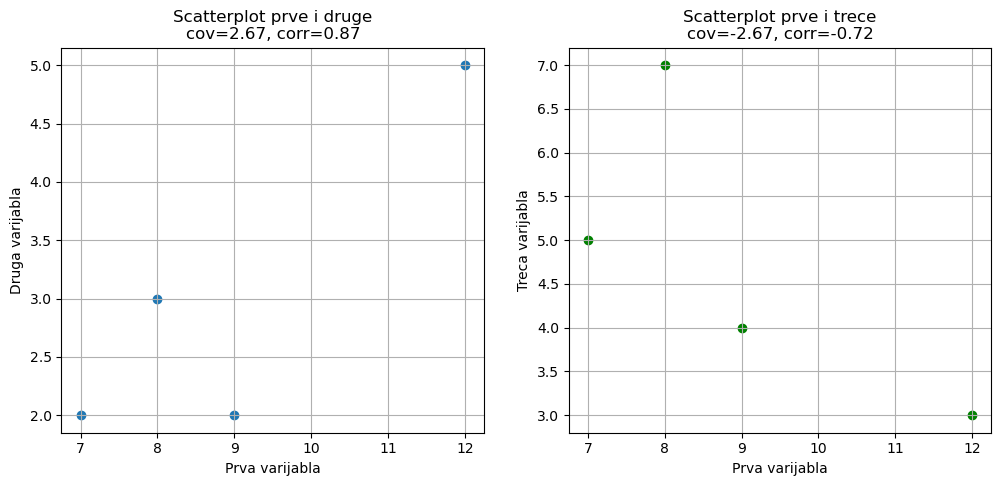

In [122]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], X[:, 1])
plt.xlabel('Prva varijabla')
plt.ylabel('Druga varijabla')
plt.title(f'Scatterplot prve i druge\ncov={S[0,1]:.2f}, corr={R[0,1]:.2f}')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.scatter(X[:, 0], X[:, 2], color='g')
plt.xlabel('Prva varijabla')
plt.ylabel('Treca varijabla')
plt.title(f'Scatterplot prve i trece\ncov={S[0,2]:.2f}, corr={R[0,2]:.2f}')
plt.grid(True)  

 Izračunajte statističku udaljenost:
 
 $$
 d\,(\mathbf{x}_1, \mathbf{x}_2) = \sqrt{(\mathbf{x}_1 - \mathbf{x}_2)^\intercal \, \mathbf{S}^{-1} (\mathbf{x}_1 - \mathbf{x}_2)}
 $$
  
 između prve i zadnje opservacije $d\,(\mathbf{x}_1, \mathbf{x}_4)$. Usporedite ju s euklidskom udaljenošću.

In [123]:
def stat_d(x1, x2, S):
    return np.sqrt((x1 - x2).T @ np.linalg.inv(S) @ (x1 - x2))

def euklid_d(x1, x2):
    return np.linalg.norm(x1 - x2)

print('Statistička udaljenost između prve i zadnje opservacije:', stat_d(X[0], X[3], S))
print('Euklidska udaljenost između njih:', euklid_d(X[0], X[3]))

Statistička udaljenost između prve i zadnje opservacije: 2.449489742783179
Euklidska udaljenost između njih: 6.164414002968976


#### (b) 
Neka $\mathbf{x}_i \in \mathbb{R}^{n \times 1}$ predstavlja vektor vrijednosti varijable $i$  (iz uzorka $\mathbf{X}$), a $\overline{x}_i$ predstavlja uzoračku srednju vrijednost varijable $i$. Za svaku varijablu $i$, izračunajte vektor devijacija (reziduala) $\mathbf{d}_i = \mathbf{x}_i - \overline{x}_i \mathbf{1}$. Usporedite duljinu vektora devijacija sa standardnom devijacijom varijable.

In [124]:
devijacije = X - x_sr_vr
for i in range(3):
    print(f"Vektor devijacija reziduala za varijablu {i+1}: {devijacije[:, i]}")

Vektor devijacija reziduala za varijablu 1: [ 3. -1.  0. -2.]
Vektor devijacija reziduala za varijablu 2: [ 2.  0. -1. -1.]
Vektor devijacija reziduala za varijablu 3: [-1.75  2.25 -0.75  0.25]


#### (c) 
Preko izračunatih vektora devijacija $\mathbf{d}_i$ rekonstruirajte matricu kovarijance $\mathbf{S}$, a zatim i matricu korelacije $\mathbf{R}$. Dokažite da su rekonstruirane matrice jednake gore izračunatima.

In [128]:
S_rekonstruirana = (devijacije.T @ d) / (n - 1)

stds = np.std(X, axis=0, ddof=1)
R_rekonstruirana = S_rekonstruirana / np.outer(stds, stds)

print("Rekonstruirana S:\n", S_rekonstruirana)
print("\nRekonstruirana  R:\n", R_rekonstruirana)


Rekonstruirana S:
 [[ 4.66666667  2.66666667 -2.66666667]
 [ 2.66666667  2.         -1.        ]
 [-2.66666667 -1.          2.91666667]]

Rekonstruirana  R:
 [[ 1.          0.87287156 -0.72280632]
 [ 0.87287156  1.         -0.41403934]
 [-0.72280632 -0.41403934  1.        ]]


#### (d) 
Izračunajte uzoračku generaliziranu varijancu $|\mathbf{S}|$ uzorka $\mathbf{X}$. Zatim dodajte novu varijablu koja je linearna kombinacija prve i druge varijable $\mathbf{x}_3 = \mathbf{x}_0 + \mathbf{x}_1$. Izračunajte uzoračku generaliziranu varijancu na novom uzorku.

In [129]:
gen_var_og = np.linalg.det(S)
print("Generalizirana varijanca originalnog uzorka:", gen_var_og)

x3 = X[:, 0] + X[:, 1] #x3 = x0 + x1
X_novo = np.column_stack((X, x3))

S_nova = np.cov(X_novo, rowvar=False, ddof=1)
gen_var_nova = np.linalg.det(S_nova)

print("Uzoračka generalizirana varijanca s novom varijablom:", gen_var_nova)

Generalizirana varijanca originalnog uzorka: 1.814814814814817
Uzoračka generalizirana varijanca s novom varijablom: 2.4544526530938638e-15


Maknite zadnju opservaciju iz originalnog uzorka $\mathbf{X}$. Izračunajte uzoračku generaliziranu varijancu i svojstvene vrijednosti na novom uzorku. Što možete zaključiti iz ovog i prethodnog primjera?

In [137]:
X_skraceni = X[:-1, :] #makni zadnju

S_skraceni = np.cov(X_skraceni, rowvar=False, ddof=1)
gen_var_skraceni = np.linalg.det(S_skraceni)
eigenvalues = np.linalg.eigvals(S_skraceni)

print("Generalizirana varijanca bez zadnje opservacije:", gen_var_skraceni)
print("Svojstvene vrijednosti:", eigenvalues)

Generalizirana varijanca bez zadnje opservacije: -4.2871689104755774e-15
Svojstvene vrijednosti: [ 9.18555740e+00 -9.21651437e-16  1.81444260e+00]


### 2. Multivarijatna normalna razdioba

Generirajte uzorak $\mathbf{X} \in \mathbb{R}^{1000x2}$ iz multivarijatne normalne razdiobe određene parametrima:

$$
\mathbf{\mu} = [2, 3],
\mathbf{\Sigma} = 
\begin{bmatrix}
10^2 & 6^2 \\
6^2 & 6^2 \\
\end{bmatrix}
$$

In [138]:
mi = np.array([2, 3])
mat_cov = np.array([[10**2, 6**2], 
                    [6**2, 6**2]])

np.random.seed(18)
uzorak = np.random.multivariate_normal(mi, mat_cov, size=1000)

print(uzorak[:10])

[[ -2.77676209  11.54734088]
 [  3.03343324   4.24771794]
 [ -3.48999648   3.57798455]
 [ -8.63897825   0.14709236]
 [  6.48580376   1.86114973]
 [ -6.67915567   1.13553204]
 [ -1.63986817  -4.01282765]
 [  9.32585073  12.85852782]
 [ -4.70116208   2.61349928]
 [-17.79388769  -7.30610632]]


#### (a) 

Prikažite graf raspršenja dviju varijabli. Na istom grafu prikažite gustoću razdiobe uz pomoć elipsi za nekoliko različitih veličina $c^2$, gdje su točke $\mathbf{x}$ sve točke koje imaju jednaku udaljenost $c^2$ od središta $\mathbf{\mu}$:

$$
c^2 =(\mathbf{x} - \mathbf{\mu})^\intercal \mathbf{\Sigma}^{-1} (\mathbf{x} - \mathbf{\mu})
$$
Pripazite da osi grafa budu na istoj skali.

**Hint**: Pogledajte `contour` funkciju u R-u, ili `plt.contour` funkciju u Pythonu (`matplotlib` biblioteka)

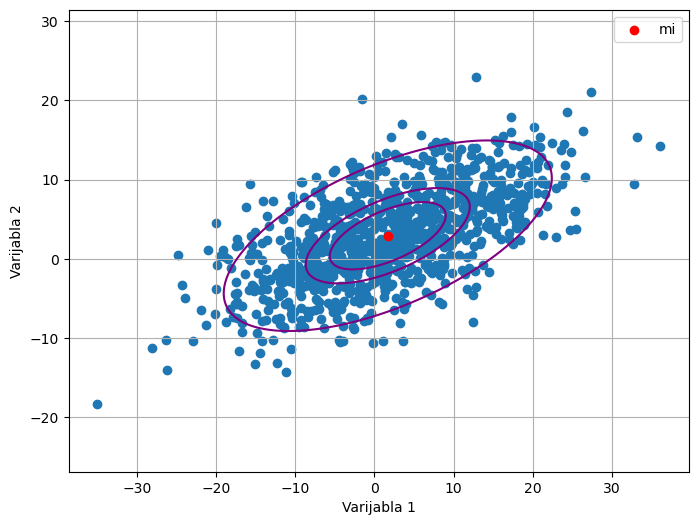

In [152]:
plt.figure(figsize=(8, 6))
plt.scatter(uzorak[:, 0], uzorak[:, 1]) 
plt.scatter(mi[0], mi[1], color='r', label='mi')
plt.xlabel('Varijabla 1')
plt.ylabel('Varijabla 2')
plt.axis('equal')  
plt.legend()
plt.grid(True)

mi = np.mean(uzorak, axis=0)
cov = np.cov(uzorak, rowvar=False)
inv_cov = np.linalg.inv(cov)


x_min, x_max = plt.xlim()
y_min, y_max = plt.ylim()
x = np.linspace(x_min, x_max, 300)
y = np.linspace(y_min, y_max, 300)
X_grid, Y_grid = np.meshgrid(x, y)

pos = np.dstack((X_grid, Y_grid))

#Mahalanobis
razl = pos - mi 
mahalanobis_d = np.sum(np.dot(razl, inv_cov) * razl, axis=-1)  

plt.contour(X_grid, Y_grid, mahalanobis_d, levels=[0.5, 1, 4], colors='purple')
plt.show()


#### (b)

Prikažite tri grafa raspršenja i pripadajućih elipsi uzorkovanjem iz multivarijatne normalne razdiobe s istim $\mu$ iz prošlog podzadatka i različitim matricama kovarijanci:

$$
\mathbf{\Sigma_1} = 
\begin{bmatrix}
10^2 & 6^2 \\
6^2 & 10^2 \\
\end{bmatrix},
\mathbf{\Sigma_2} = 
\begin{bmatrix}
10^2 & 7^2 \\
7^2 & 6^2 \\
\end{bmatrix}
\mathbf{\Sigma_3} = 
\begin{bmatrix}
10^2 & 8^2 \\
8^2 & 6^2 \\
\end{bmatrix}
$$
Ukoliko nije moguće prikazati grafove raspršenja, pokažite zašto.

In [140]:
cov1 = np.array([[10**2, 6**2], 
                 [6**2, 10**2]])

cov2 = np.array([[10**2, 7**2], 
                 [7**2, 6**2]])

cov3 = np.array([[10**2, 8**2], 
                 [8**2, 6**2]])

In [159]:
np.random.seed(18) 
uzorak1 = np.random.multivariate_normal(mi, cov1, size=1000) #mi=[2,3] iz prethodnog zad
uzorak2 = np.random.multivariate_normal(mi, cov2, size=1000)
uzorak3 = np.random.multivariate_normal(mi, cov3, size=1000)

C:\Users\Home\AppData\Local\Temp\ipykernel_15600\4047529690.py:4: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  uzorak3 = np.random.multivariate_normal(mi, cov3, size=1000)


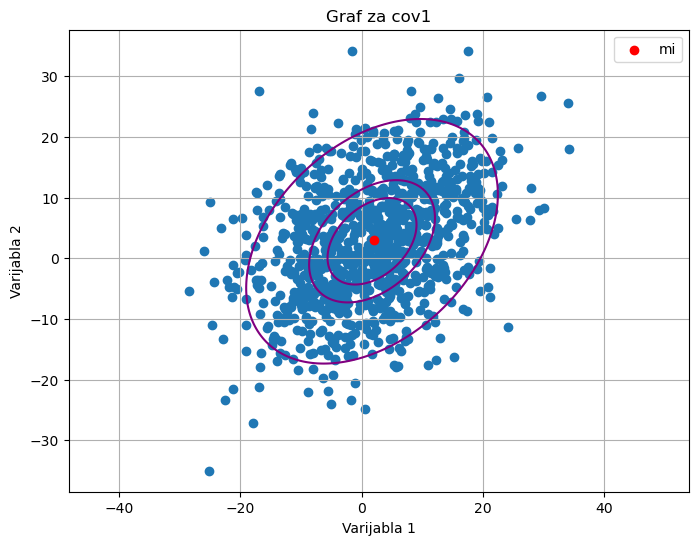

In [156]:
plt.figure(figsize=(8, 6))
plt.scatter(uzorak1[:, 0], uzorak1[:, 1])
plt.scatter(mi[0], mi[1], color='r', label='mi')
plt.xlabel('Varijabla 1')
plt.ylabel('Varijabla 2')
plt.axis('equal')
plt.legend()
plt.grid(True)

mi1 = np.mean(uzorak1, axis=0)
cov1_calc = np.cov(uzorak1, rowvar=False)
inv_cov1 = np.linalg.inv(cov1_calc)

x_min, x_max = plt.xlim()
y_min, y_max = plt.ylim()
x = np.linspace(x_min, x_max, 300)
y = np.linspace(y_min, y_max, 300)
X_grid, Y_grid = np.meshgrid(x, y)

pos = np.dstack((X_grid, Y_grid))

razl = pos - mi1
mahalanobis_d = np.sum(np.dot(razl, inv_cov1) * razl, axis=-1)

plt.contour(X_grid, Y_grid, mahalanobis_d, levels=[0.5, 1, 4], colors='purple')
plt.title('Graf za cov1')
plt.show()


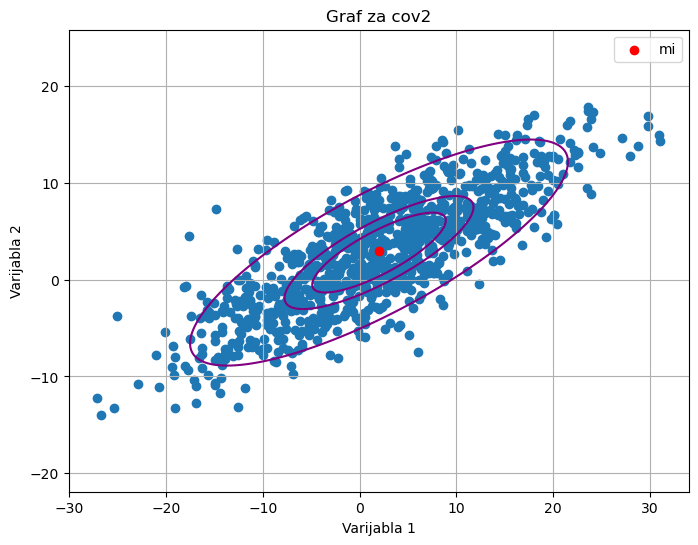

In [157]:
plt.figure(figsize=(8, 6))
plt.scatter(uzorak2[:, 0], uzorak2[:, 1])
plt.scatter(mi[0], mi[1], color='r', label='mi')
plt.xlabel('Varijabla 1')
plt.ylabel('Varijabla 2')
plt.axis('equal')
plt.legend()
plt.grid(True)

mi2 = np.mean(uzorak2, axis=0)
cov2_calc = np.cov(uzorak2, rowvar=False)
inv_cov2 = np.linalg.inv(cov2_calc)

x_min, x_max = plt.xlim()
y_min, y_max = plt.ylim()
x = np.linspace(x_min, x_max, 300)
y = np.linspace(y_min, y_max, 300)
X_grid, Y_grid = np.meshgrid(x, y)

pos = np.dstack((X_grid, Y_grid))

razl = pos - mi2
mahalanobis_d = np.sum(np.dot(razl, inv_cov2) * razl, axis=-1)

plt.contour(X_grid, Y_grid, mahalanobis_d, levels=[0.5, 1, 4], colors='purple')
plt.title('Graf za cov2')
plt.show()


#### (c)

Promatramo $\mathbf{\Sigma}_1$ i $\mathbf{\Sigma}_2$ iz prošlog podzadatka. Neka su $\mathbf{X}_1 \sim \mathbf{\mathcal{N}}(\mathbf{\mu, \mathbf{\Sigma}_1)}$ i $\mathbf{X}_2 \sim \mathbf{\mathcal{N}}(\mathbf{\mu, \mathbf{\Sigma}_2)}$ slučajni dvo-dimenzionalni vektori, i neka je $\mathbf{X}_r$ slučajni vektor određen izrazom $\mathbf{X}_r = \mathbf{X}_1 - \mathbf{X}_2$. Odredite populacijske parametre koji određuju $\mathbf{X}_r \sim \mathbf{\mathcal{N}}(\mathbf{\mu}_r, \mathbf{\Sigma}_r)$.

In [ ]:
# <Vaš kôd ovdje>

Procjenite iste te parametre uzorkovanjem $n=10^7$ opservacija iz $\mathbf{X_1}$ i $\mathbf{X_2}$.

In [ ]:
# <Vaš kôd ovdje>

Procjenite parametre procjenitelja $\overline{\mathbf{X}}_r \sim \mathbf{\mathcal{N}}(\mathbf{\mu}_r, (1/n)\mathbf{\Sigma}_r)$ uzorkovanjem iz $\mathbf{X_1}$ i $\mathbf{X_2}$ na sljedeći način: generirajte $K = 10^5$ uzoraka, gdje svaki uzorak ima $n = 100$ opservacija.

In [ ]:
# <Vaš kôd ovdje>

### 3. Statističko zaključivanje

Generirajte uzorak $\mathbf{X} \in \mathbb{R}^{1000x2}$ iz multivarijatne normalne razdiobe s parametrima:

$$
\mathbf{\mu} = [2, 3],
\mathbf{\Sigma} = 
\begin{bmatrix}
10^2 & 7^2 \\
7^2 & 6^2 \\
\end{bmatrix}
$$

In [78]:
mi = np.array([2, 3])
mat_cov = np.array([[10**2, 7**2], 
                    [7**2, 6**2]])

np.random.seed(18)
uzorak = np.random.multivariate_normal(mi, mat_cov, size=1000)

print(uzorak[:10])

[[ -1.99525509   8.50407136]
 [  3.09913459   4.1568417 ]
 [ -3.29271168   2.31722532]
 [ -8.55785588  -1.33487732]
 [  6.27407075   3.05257587]
 [ -6.57788426  -0.18543771]
 [ -2.06976433  -3.05928855]
 [  9.86844243  11.96907492]
 [ -4.54313832   1.33880147]
 [-18.02187851  -8.85402502]]


#### (a)

Implementirajte funkciju za određivanje *Hotellingove $T^2$* statistike.

In [79]:
def hotelling_T2(uzorak, mi_0, S):
    n, p = uzorak.shape
    razlika = np.mean(uzorak, axis=0) - mi_0
    T2 = n * razlika.T @ np.linalg.inv(S) @ razlika
    return T2

Za generirani uzorak testirajte hiptezu $H_0: \mathbf{\mu}= [2, 3]$ naspram $H_1: \mathbf{\mu} \neq [2, 3]$ za razinu značajnosti $\alpha = 0.05$.

In [80]:
from scipy.stats import f

alpha = 0.05
n, p = uzorak.shape


F_krit = f.ppf(1 - alpha, dfn=p, dfd=n - p)
T2_krit = ((n - 1) * p / (n - p)) * F_krit 

print(f"Hotelling T^2 = {T2:.4f}")
print(f"Kritična vrijednost T^2 = {T2_krit:.4f}")

T2 = hotelling_T2(uzorak, mi, mat_cov)
if T2 > T2_krit:
    print("Na razini značajnosti 0.05 odbacujemo H0 u korist H1")
else:
    print("Na razini značajnosti 0.05 nemožemo odbaciti H0")


Hotelling T^2 = 0.9259
Kritična vrijednost T^2 = 6.0155
Na razini značajnosti 0.05 nemožemo odbaciti H0


#### (b)

Za generirani uzorak, prikažite na grafu $95\%$-tno područje pouzdanosti za $\mathbf{\mu}$ razdiobe.

In [ ]:
# <Vaš kôd ovdje>

#### (c)

Uz pomoć simultanih intervala pouzdanosti ($T^2$-interval), odredite $95\%$-tno područje pouzdanosti za srednje vrijednosti varijabli, $\mu_1$ i $\mu_2$, te njihovu razliku $\mu_2 - \mu_1$.

In [84]:
x_sredina = np.mean(uzorak, axis=0)

S = np.cov(uzorak, rowvar=False)
c = np.sqrt((p * (n - 1)) / (n * (n - p)) * F_krit)

s11 = S[0, 0]
s22 = S[1, 1]
s12 = S[0, 1]

SE_1 = np.sqrt(s11)
SE_2 = np.sqrt(s22)

interval_1 = (x_sredina[0] - c * SE_1, x_sredina[0] + c * SE_1)
interval_2 = (x_sredina[1] - c * SE_2, x_sredina[1] + c * SE_2)

diff_mean = x_sredina[1] - x_sredina[0]
SE_diff = np.sqrt(s11 + s22 - 2 * s12)
interval_diff = (diff_mean - c * SE_diff, diff_mean + c * SE_diff)

print("95% simultani T2 intervali:")
print(f"μ1 [{interval_1}]")
print(f"μ2 [{interval_2}]")
print(f"μ2 - μ1 [{interval_diff}]")

95% simultani T2 intervali:
μ1 [(0.8957586025932678, 2.5016332468811244)]
μ2 [(2.3956441427680506, 3.3385333489499365)]
μ2 - μ1 [(0.6738350547136569, 1.6629505875299382)]


Izračunajte univarijatni $t$-interval pouzdanosti za srednju vrijednost svake varijable, a zatim i Bonferronijevu korekciju $t$-intervala. Usporedite s rezultatima dobivenim pomoću $T^2$-intervala.

In [85]:
from scipy.stats import t
np.random.seed(18)

#Univarijatni t
t_krit = t.ppf(1 - alpha / 2, df=n - 1)
t_int_1 = (x_sredina[0] - t_krit * np.sqrt(s11 / n),  x_sredina[0] + t_krit * np.sqrt(s11 / n))
t_int_2 = (x_sredina[1] - t_krit * np.sqrt(s22 / n),  x_sredina[1] + t_krit * np.sqrt(s22 / n))

#Bonferroni
alpha_bonf = alpha / p
t_bonf = t.ppf(1 - alpha_bonf / 2, df=n - 1)
t_bonf_1 = (x_sredina[0] - t_bonf * np.sqrt(s11 / n),  x_sredina[0] + t_bonf * np.sqrt(s11 / n))
t_bonf_2 = (x_sredina[1] - t_bonf * np.sqrt(s22 / n),  x_sredina[1] + t_bonf * np.sqrt(s22 / n))

print("Univarijatni t-intervali")
print(f"μ1  [{t_int_1}]")
print(f"μ2  [{t_int_2}]")

print("\nBonferronijevi")
print(f"μ1 [{t_bonf_1}]")
print(f"μ2 [{t_bonf_2}]")

Univarijatni t-intervali
μ1  [(1.0562743612194176, 2.3411174882549743)]
μ2  [(2.4898909613282942, 3.244286530389693)]

Bonferronijevi
μ1 [(0.9638089114237677, 2.433582938050624)]
μ2 [(2.4355998777327037, 3.2985776139852834)]


Izračunajte $\tilde{\chi}^2$ interval pouzdanosti za velike uzorke za srednju vrijednost svake varijable. Usporedite dobivenu vrijednost s prethodno dobivenim vrijednostima.

In [86]:
from scipy.stats import norm

z_krit = norm.ppf(1 - alpha / 2)

X2_int_1 = (x_sredina[0] - z_krit * np.sqrt(s11 / n),   x_sredina[0] + z_krit * np.sqrt(s11 / n))
X2_int_2 = (x_sredina[1] - z_krit * np.sqrt(s22 / n),   x_sredina[1] + z_krit * np.sqrt(s22 / n))

print("X² intervali pouzdanosti za velike uzorke:")
print(f"μ1 [{X2_int_1}]")
print(f"μ2 [{X2_int_2}]")

X² intervali pouzdanosti za velike uzorke:
μ1 [(1.0570526876527149, 2.340339161821677)]
μ2 [(2.490347955649397, 3.2438295360685903)]
